<a href="https://colab.research.google.com/github/anvithakomarraju/monet-color-dna/blob/main/monet_color_dna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests, numpy as np, pandas as pd
from PIL import Image
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
print("all good")

all good


In [ ]:
import requests
import tarfile
import json
from pathlib import Path

archive_path = Path("artic-api-data.tar.bz2")
dataset_url = (
    "https://artic-api-data.s3.amazonaws.com/"
    "artic-api-data.tar.bz2"
)

# Save the download so rerunning this cell doesn't download it again.
if not archive_path.exists():
    print("Downloading the museum dataset. This may take a few minutes...")
    temporary_path = archive_path.with_suffix(".part")

    with requests.get(
        dataset_url, stream=True, timeout=(15, 120)
    ) as response:
        response.raise_for_status()

        with temporary_path.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    temporary_path.replace(archive_path)

print("Looking for Monet artworks...")

paintings = []

with tarfile.open(archive_path, mode="r|bz2") as archive:
    for member in archive:
        if not member.isfile():
            continue

        # Ignore records for artists, exhibitions, and other resources.
        if (
            "/artworks/" not in "/" + member.name
            or not member.name.endswith(".json")
        ):
            continue

        with archive.extractfile(member) as file:
            artwork = json.load(file)

        if (
            artwork.get("artist_title") == "Claude Monet"
            and artwork.get("image_id")
            and artwork.get("is_public_domain")
            and artwork.get("date_start") is not None
        ):
            paintings.append(artwork)

paintings.sort(key=lambda p: (p["date_start"], p["id"]))

print(f"\nFound {len(paintings)} usable Monet artworks.")

for painting in paintings[:5]:
    print(painting["date_start"], "—", painting["title"])

Looking for Monet artworks...

Found 46 usable Monet artworks.
1855 — Caricature of a Man with a Big Cigar
1855 — Caricature of a Man in the Small Hat
1855 — Caricature of Auguste Vacquerie
1855 — Caricature of a Man Standing by Desk (recto); Sketch of Male Head in Profile (verso)
1855 — Caricature of a Man with a Large Nose


In [ ]:
# Keep paintings, excluding drawings and caricatures.
monet_paintings = [
    p for p in paintings
    if (p.get("artwork_type_title") or "").lower() == "painting"
]

print(f"Found {len(monet_paintings)} paintings.")

for p in monet_paintings[:5]:
    print(p["date_start"], "—", p["title"])

Found 33 paintings.
1867 — The Beach at Sainte-Adresse
1868 — On the Bank of the Seine, Bennecourt
1873 — The Artist's House at Argenteuil
1877 — Arrival of the Normandy Train, Gare Saint-Lazare
1880 — Apples and Grapes


In [ ]:
first = monet_paintings[0]
print(first["title"])
print(f"https://www.artic.edu/artworks/{first['id']}")

The Beach at Sainte-Adresse
https://www.artic.edu/artworks/14598


Saving default.jpg to default.jpg


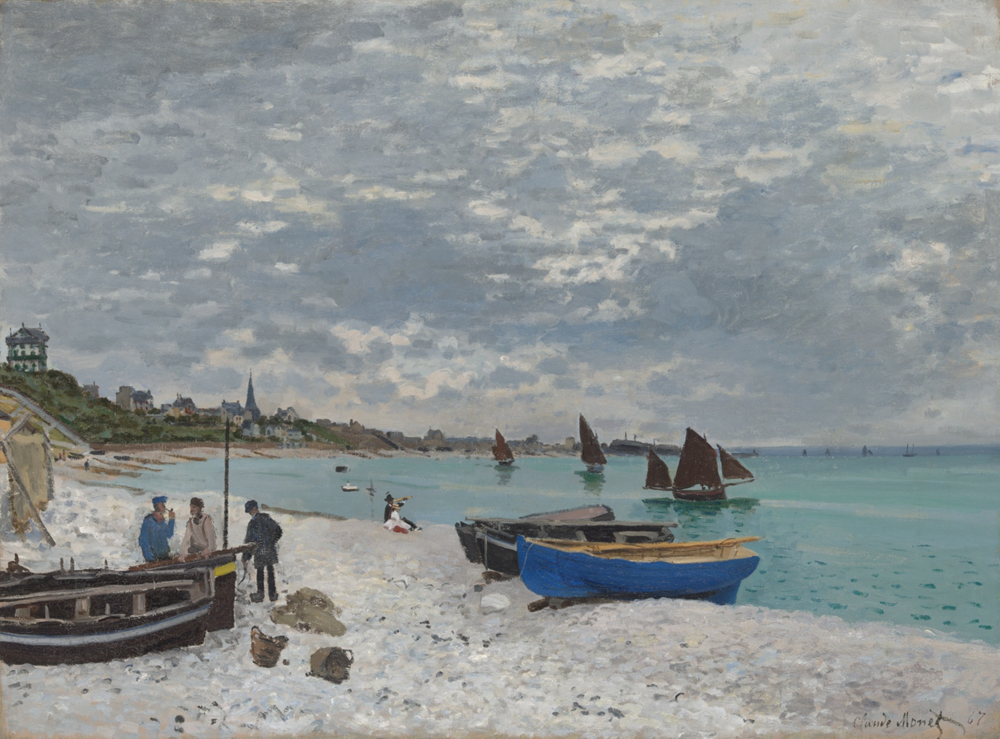

In [ ]:
from google.colab import files
from PIL import Image
from io import BytesIO
from IPython.display import display

uploaded = files.upload()

filename = next(iter(uploaded))
first_image = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

display(first_image)

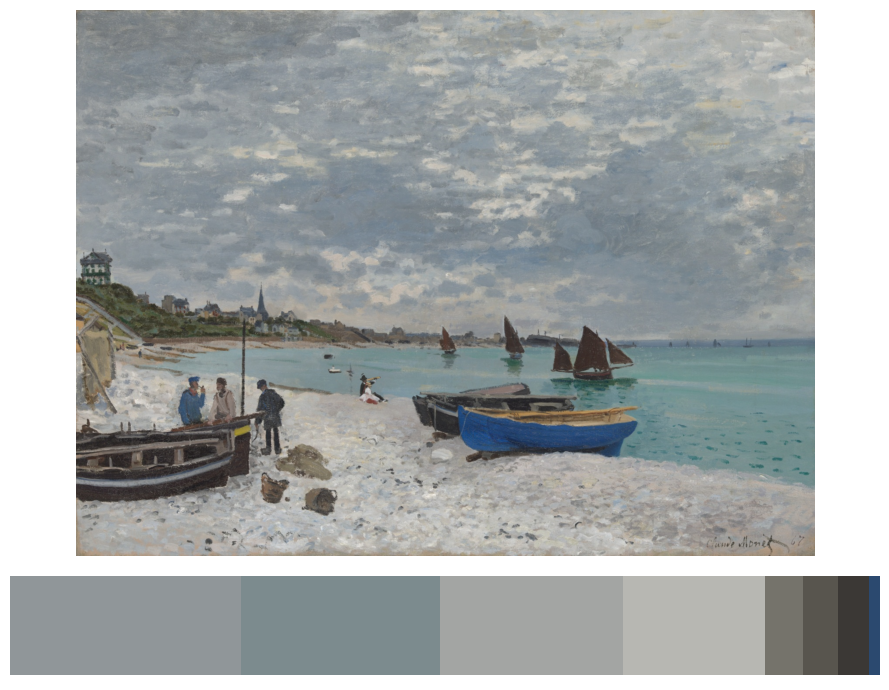

#909699: 26.6%
#7c8b8e: 22.8%
#a3a5a3: 21.1%
#b7b7b2: 16.2%
#75736b: 4.4%
#58554e: 3.9%
#3b3835: 3.7%
#2b496f: 1.2%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Shrink a copy while preserving the painting's proportions.
small = first_image.copy()
small.thumbnail((200, 200))

# Turn the image into a list of RGB pixel colors.
pixels = np.asarray(small).reshape(-1, 3)

# Group similar colors into five clusters.
model = KMeans(n_clusters=8, n_init=10, random_state=0)
model.fit(pixels)

# Sort colors by how much of the image they represent.
counts = np.bincount(model.labels_, minlength=8)
order = np.argsort(-counts)

palette = np.clip(
    np.rint(model.cluster_centers_[order]), 0, 255
).astype("uint8")

proportions = counts[order] / counts.sum()

# Show the painting and its palette.
fig, (art_ax, palette_ax) = plt.subplots(
    2, 1, figsize=(9, 7),
    gridspec_kw={"height_ratios": [5, 1]}
)

art_ax.imshow(first_image)
art_ax.axis("off")

left = 0
for color, proportion in zip(palette, proportions):
    palette_ax.barh(
        0, proportion, left=left,
        color=color / 255, height=1
    )
    left += proportion

palette_ax.set_xlim(0, 1)
palette_ax.axis("off")

plt.tight_layout()
plt.savefig("first_monet_palette.png", dpi=200, bbox_inches="tight")
plt.show()

for color, proportion in zip(palette, proportions):
    hex_color = "#" + "".join(f"{int(c):02x}" for c in color)
    print(f"{hex_color}: {proportion:.1%}")

In [ ]:
results = [{
    "title": first["title"],
    "year": first["date_start"],
    "image": first_image.copy(),
    "palette": palette.copy(),
    "proportions": proportions.copy(),
}]

In [ ]:
for i, p in enumerate(monet_paintings):
    print(f"{i}: {p['date_start']} — {p['title']}")

0: 1867 — The Beach at Sainte-Adresse
1: 1868 — On the Bank of the Seine, Bennecourt
2: 1873 — The Artist's House at Argenteuil
3: 1877 — Arrival of the Normandy Train, Gare Saint-Lazare
4: 1880 — Apples and Grapes
5: 1882 — Cliff Walk at Pourville
6: 1884 — Bordighera
7: 1885 — Étretat: The Beach and the Falaise d'Amont
8: 1885 — Boats on the Beach at Étretat
9: 1885 — The Departure of the Boats, Étretat
10: 1886 — Rocks at Port-Goulphar, Belle-Île
11: 1889 — The Petite Creuse River
12: 1890 — Poppy Field (Giverny)
13: 1890 — Stacks of Wheat (End of Day, Autumn)
14: 1890 — Stack of Wheat (Snow Effect, Overcast Day)
15: 1890 — Stacks of Wheat (End of Summer)
16: 1890 — Stacks of Wheat (Sunset, Snow Effect)
17: 1890 — Stack of Wheat (Thaw, Sunset)
18: 1890 — Stack of Wheat
19: 1895 — Sandvika, Norway
20: 1897 — The Customs House at Varengeville
21: 1897 — Branch of the Seine near Giverny (Mist)
22: 1900 — Houses of Parliament, London
23: 1900 — Water Lily Pond
24: 1900 — Waterloo Bridge

In [ ]:
second = monet_paintings[31]  # Change 1 to your chosen number

print(second["title"])
print(f"https://www.artic.edu/artworks/{second['id']}")

Irises
https://www.artic.edu/artworks/4887


Saving irises.jpg to irises.jpg


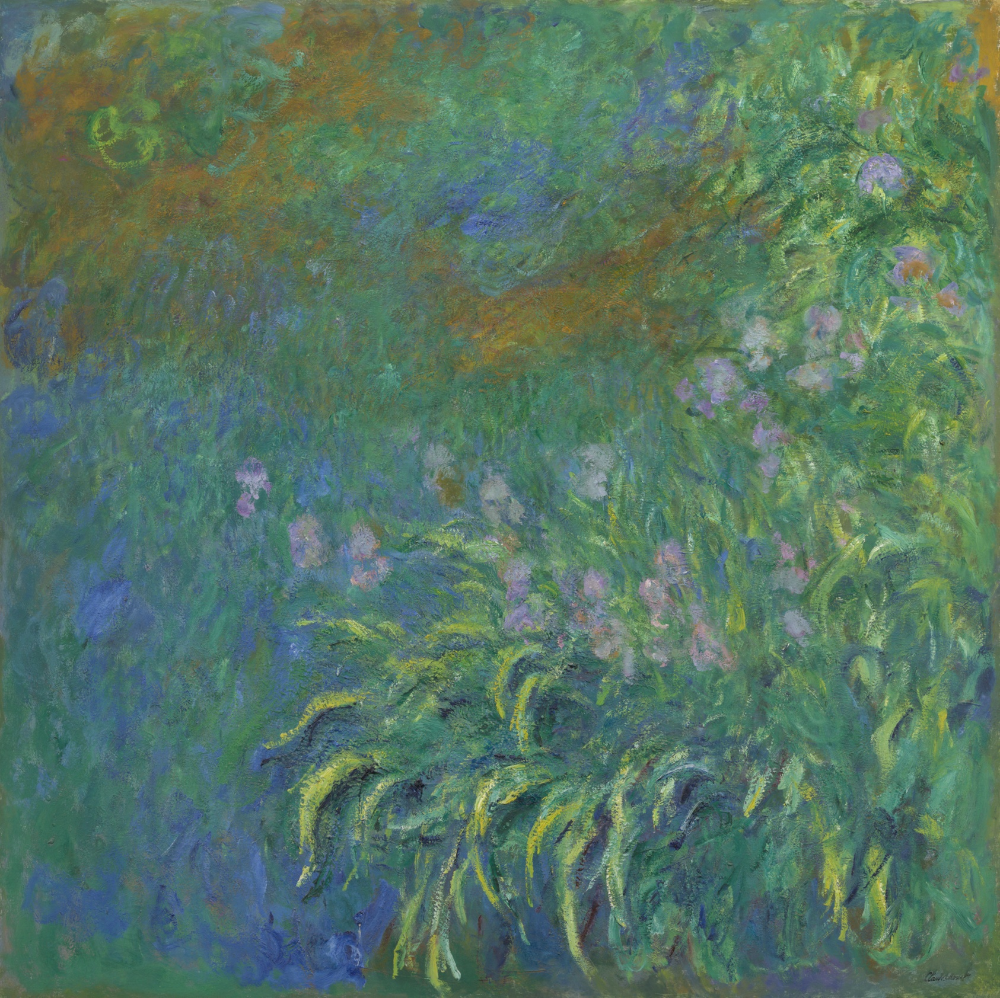

In [ ]:
uploaded = files.upload()
filename = next(iter(uploaded))

second_image = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

display(second_image)

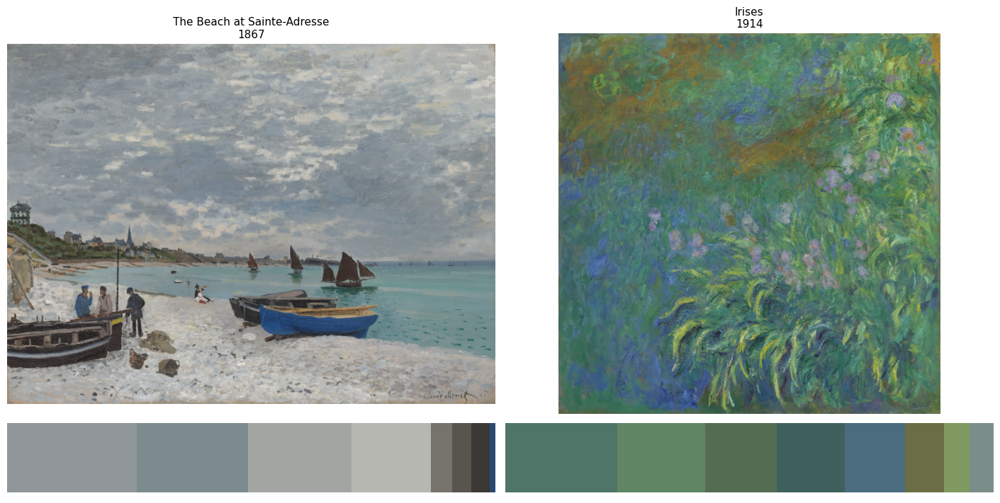

In [ ]:
def extract_palette(image, k=8):
    small = image.copy()
    small.thumbnail((200, 200))
    pixels = np.asarray(small).reshape(-1, 3)

    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(pixels)

    counts = np.bincount(model.labels_, minlength=k)
    order = np.argsort(-counts)

    colors = np.clip(
        np.rint(model.cluster_centers_[order]), 0, 255
    ).astype("uint8")

    proportions = counts[order] / counts.sum()
    return colors, proportions


# Compute both with the same settings.
comparison = []

for artwork, image in [
    (first, first_image),
    (second, second_image),
]:
    colors, shares = extract_palette(image)
    comparison.append({
        "title": artwork["title"],
        "year": artwork["date_start"],
        "image": image.copy(),
        "palette": colors,
        "proportions": shares,
    })

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 7),
    gridspec_kw={"height_ratios": [5, 1]},
    constrained_layout=True,
)

for column, item in enumerate(comparison):
    axes[0, column].imshow(item["image"])
    axes[0, column].set_title(
        f"{item['title']}\n{item['year']}", fontsize=11
    )
    axes[0, column].axis("off")

    left = 0
    for color, share in zip(item["palette"], item["proportions"]):
        axes[1, column].barh(
            0, share, left=left, color=color / 255, height=1
        )
        left += share

    axes[1, column].set_xlim(0, 1)
    axes[1, column].axis("off")

fig.savefig("monet_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Save both results for the larger collection.
results = comparison

Search status: 200
Image status: 200
File:Claude Monet - The Beach at Sainte-Adresse - Google Art Project.jpg
Source: https://commons.wikimedia.org/wiki/File:Claude_Monet_-_The_Beach_at_Sainte-Adresse_-_Google_Art_Project.jpg


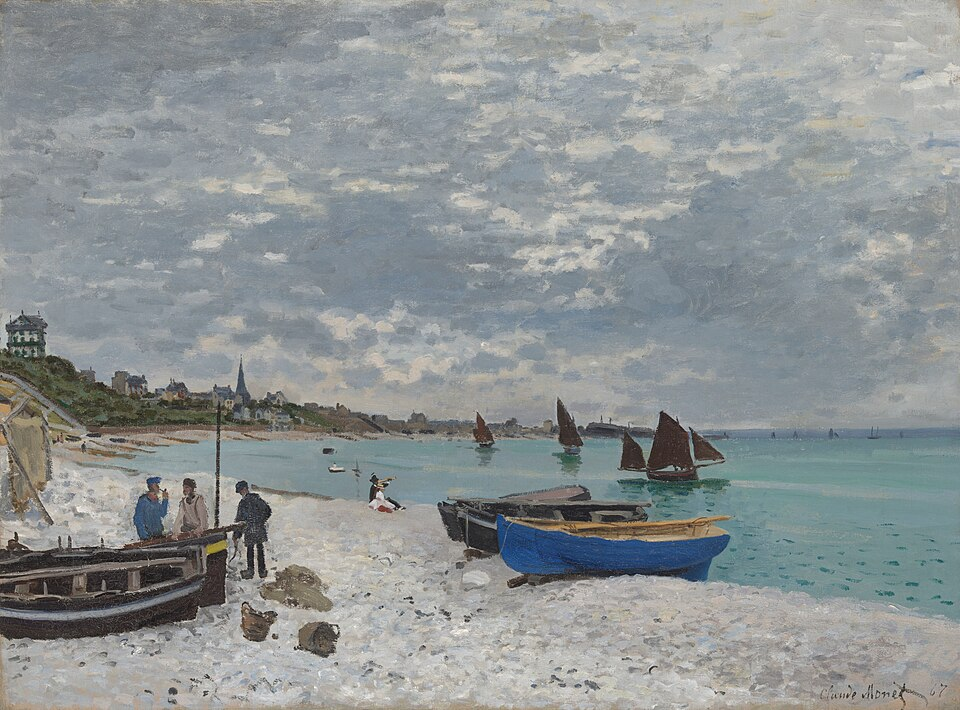

In [ ]:
import requests
from PIL import Image
from io import BytesIO
from IPython.display import display

commons = requests.Session()
commons.headers["User-Agent"] = "MonetPaletteStudy/0.1 (educational notebook)"

response = commons.get(
    "https://commons.wikimedia.org/w/api.php",
    params={
        "action": "query",
        "format": "json",
        "generator": "search",
        "gsrsearch": 'Claude Monet "Beach at Sainte-Adresse"',
        "gsrnamespace": 6,  # Search image files
        "gsrlimit": 3,
        "prop": "imageinfo",
        "iiprop": "url",
        "iiurlwidth": 960,
    },
    timeout=60,
)

print("Search status:", response.status_code)
response.raise_for_status()

data = response.json()
if "error" in data:
    raise RuntimeError(data["error"])

pages = sorted(
    data.get("query", {}).get("pages", {}).values(),
    key=lambda p: p.get("index", 999),
)

candidates = [p for p in pages if p.get("imageinfo")]

if not candidates:
    print("No matching images found. Send me this output.")
else:
    candidate = candidates[0]
    info = candidate["imageinfo"][0]
    download_url = info.get("thumburl") or info["url"]

    image_response = commons.get(download_url, timeout=60)
    print("Image status:", image_response.status_code)
    image_response.raise_for_status()

    commons_test_image = Image.open(
        BytesIO(image_response.content)
    ).convert("RGB")

    print(candidate["title"])
    print("Source:", info["descriptionurl"])
    display(commons_test_image)


Searching: On the Bank of the Seine, Bennecourt (1868)
Preview number: 0
Found: File:Claude Monet River Scene at Bennecourt, Seine.jpg
Commons: https://commons.wikimedia.org/wiki/File:Claude_Monet_River_Scene_at_Bennecourt,_Seine.jpg
Museum: https://www.artic.edu/artworks/81539


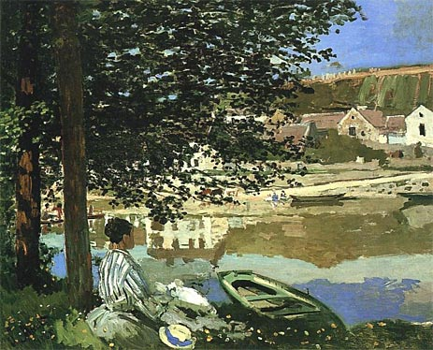


Searching: Rocks at Port-Goulphar, Belle-Île (1886)
Preview number: 1
Found: File:Rocks at Port-Goulphar, Belle-Île Claude Monet MASP 2025 - São Paulo - A Ecologia de Monet.jpg
Commons: https://commons.wikimedia.org/wiki/File:Rocks_at_Port-Goulphar,_Belle-%C3%8Ele_Claude_Monet_MASP_2025_-_S%C3%A3o_Paulo_-_A_Ecologia_de_Monet.jpg
Museum: https://www.artic.edu/artworks/20545


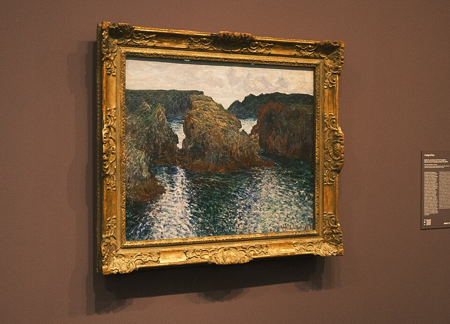


Searching: The Customs House at Varengeville (1897)
Preview number: 2
Found: File:Monet - The Customs House at Varengeville, 1897.jpg
Commons: https://commons.wikimedia.org/wiki/File:Monet_-_The_Customs_House_at_Varengeville,_1897.jpg
Museum: https://www.artic.edu/artworks/16542


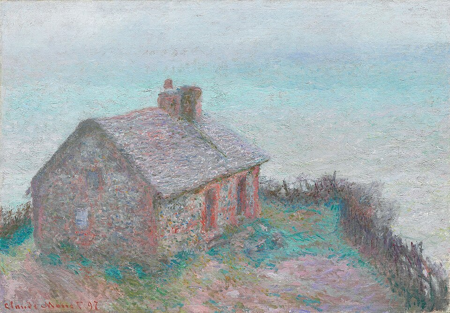


Searching: Venice, Palazzo Dario (1908)
Preview number: 3
Found: File:Monet - Venice, Palazzo Dario, 1908.jpg
Commons: https://commons.wikimedia.org/wiki/File:Monet_-_Venice,_Palazzo_Dario,_1908.jpg
Museum: https://www.artic.edu/artworks/14630


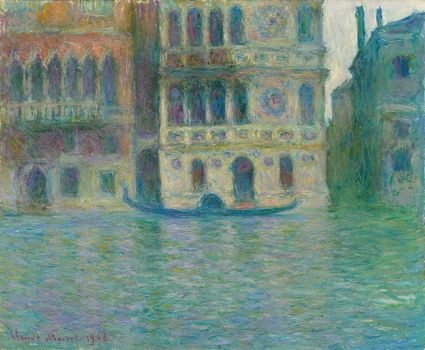

In [ ]:
import time

# Choose up to four paintings spread across the intervening years.
options = [
    p for p in monet_paintings
    if first["date_start"] < p["date_start"] < second["date_start"]
    and p["id"] not in {first["id"], second["id"]}
]

options.sort(key=lambda p: (p["date_start"], p["id"]))

indices = (
    np.linspace(0, len(options) - 1, min(4, len(options)), dtype=int)
    if options else []
)

pending = []

for index in indices:
    artwork = options[index]
    print(f"\nSearching: {artwork['title']} ({artwork['date_start']})")

    try:
        response = commons.get(
            "https://commons.wikimedia.org/w/api.php",
            params={
                "action": "query",
                "format": "json",
                "generator": "search",
                "gsrsearch": f'Claude Monet "{artwork["title"]}"',
                "gsrnamespace": 6,
                "gsrlimit": 3,
                "prop": "imageinfo",
                "iiprop": "url",
                "iiurlwidth": 960,
            },
            timeout=60,
        )
        response.raise_for_status()
        data = response.json()

        if "error" in data:
            raise RuntimeError(data["error"])

        pages = sorted(
            data.get("query", {}).get("pages", {}).values(),
            key=lambda p: p.get("index", 999),
        )
        candidates = [p for p in pages if p.get("imageinfo")]

        if not candidates:
            print("No match found; skipping.")
            continue

        candidate = candidates[0]
        info = candidate["imageinfo"][0]

        image_response = commons.get(
            info.get("thumburl") or info["url"],
            timeout=60,
        )
        image_response.raise_for_status()

        image = Image.open(
            BytesIO(image_response.content)
        ).convert("RGB")

        pending.append({
            "artwork": artwork,
            "image": image,
            "source": info["descriptionurl"],
            "file_title": candidate["title"],
        })

        print(f"Preview number: {len(pending) - 1}")
        print("Found:", candidate["title"])
        print("Commons:", info["descriptionurl"])
        print("Museum:", f"https://www.artic.edu/artworks/{artwork['id']}")

        preview = image.copy()
        preview.thumbnail((450, 350))
        display(preview)

    except (requests.RequestException, ValueError, OSError, RuntimeError) as error:
        print("Couldn't load this one:", error)

    finally:
        time.sleep(1)

Alternative 0: File:Bloc de rochers à Port-Goulphar (1887) Claude Monet (W1096).jpg
https://commons.wikimedia.org/wiki/File:Bloc_de_rochers_%C3%A0_Port-Goulphar_(1887)_Claude_Monet_(W1096).jpg


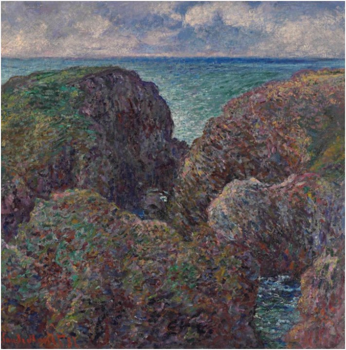

Alternative 1: File:Monet w1097.jpg
https://commons.wikimedia.org/wiki/File:Monet_w1097.jpg


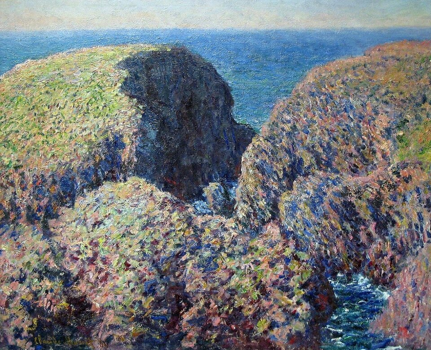

Alternative 2: File:Claude monet, scogli a port-goulphar, belle-ile, 1886, 02.jpg
https://commons.wikimedia.org/wiki/File:Claude_monet,_scogli_a_port-goulphar,_belle-ile,_1886,_02.jpg


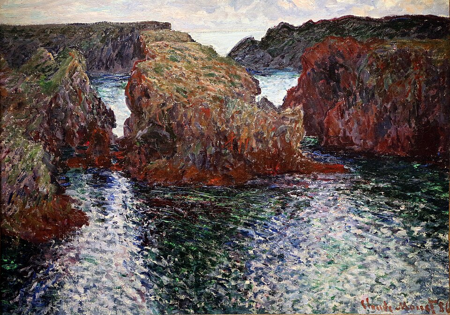

Alternative 3: File:Claude monet, scogli a port-goulphar, belle-ile, 1886, 01.jpg
https://commons.wikimedia.org/wiki/File:Claude_monet,_scogli_a_port-goulphar,_belle-ile,_1886,_01.jpg


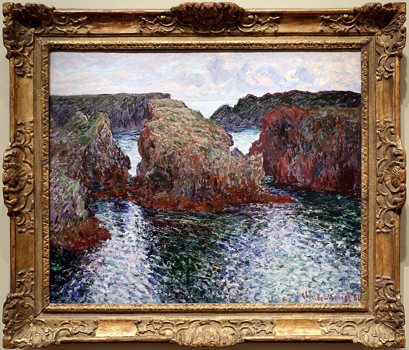

Alternative 4: File:Claude Monet - Port-Goulphar, Belle-Île - Google Art Project.jpg
https://commons.wikimedia.org/wiki/File:Claude_Monet_-_Port-Goulphar,_Belle-%C3%8Ele_-_Google_Art_Project.jpg


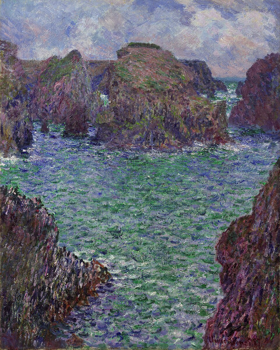

Alternative 5: File:Monet - Wildenstein 1996, 1098.png
https://commons.wikimedia.org/wiki/File:Monet_-_Wildenstein_1996,_1098.png


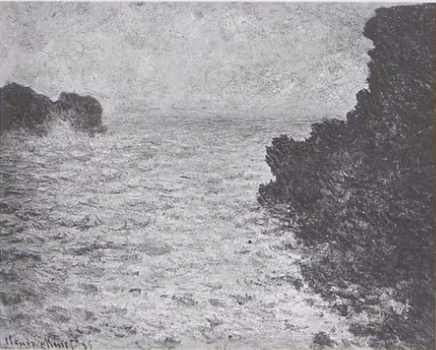

In [ ]:
artwork = pending[1]["artwork"]

response = commons.get(
    "https://commons.wikimedia.org/w/api.php",
    params={
        "action": "query",
        "format": "json",
        "generator": "search",
        "gsrsearch": 'Monet "Port-Goulphar" -MASP',
        "gsrnamespace": 6,
        "gsrlimit": 6,
        "prop": "imageinfo",
        "iiprop": "url",
        "iiurlwidth": 960,
    },
    timeout=60,
)
response.raise_for_status()
data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

pages = sorted(
    data.get("query", {}).get("pages", {}).values(),
    key=lambda p: p.get("index", 999),
)

alternatives = []

for page in pages:
    if not page.get("imageinfo"):
        continue

    info = page["imageinfo"][0]

    try:
        r = commons.get(info.get("thumburl") or info["url"], timeout=60)
        r.raise_for_status()
        image = Image.open(BytesIO(r.content)).convert("RGB")

        alternatives.append({
            "artwork": artwork,
            "image": image,
            "source": info["descriptionurl"],
            "file_title": page["title"],
        })

        print(f"Alternative {len(alternatives) - 1}: {page['title']}")
        print(info["descriptionurl"])

        preview = image.copy()
        preview.thumbnail((450, 350))
        display(preview)

    except (requests.RequestException, OSError) as error:
        print("Skipped:", error)

    finally:
        time.sleep(1)

In [ ]:
# Start with the original two paintings.
results = [item.copy() for item in comparison]

for item in pending:
    artwork = item["artwork"]
    colors, shares = extract_palette(item["image"], k=8)

    results.append({
        "title": artwork["title"],
        "year": artwork["date_start"],
        "image": item["image"].copy(),
        "palette": colors,
        "proportions": shares,
        "source": item["source"],
        "file_title": item["file_title"],
    })

results.sort(key=lambda item: item["year"])

print(f"Saved {len(results)} paintings:")
for item in results:
    print(item["year"], "—", item["title"])

Saved 6 paintings:
1867 — The Beach at Sainte-Adresse
1868 — On the Bank of the Seine, Bennecourt
1886 — Rocks at Port-Goulphar, Belle-Île
1897 — The Customs House at Varengeville
1908 — Venice, Palazzo Dario
1914 — Irises


Replacement image:


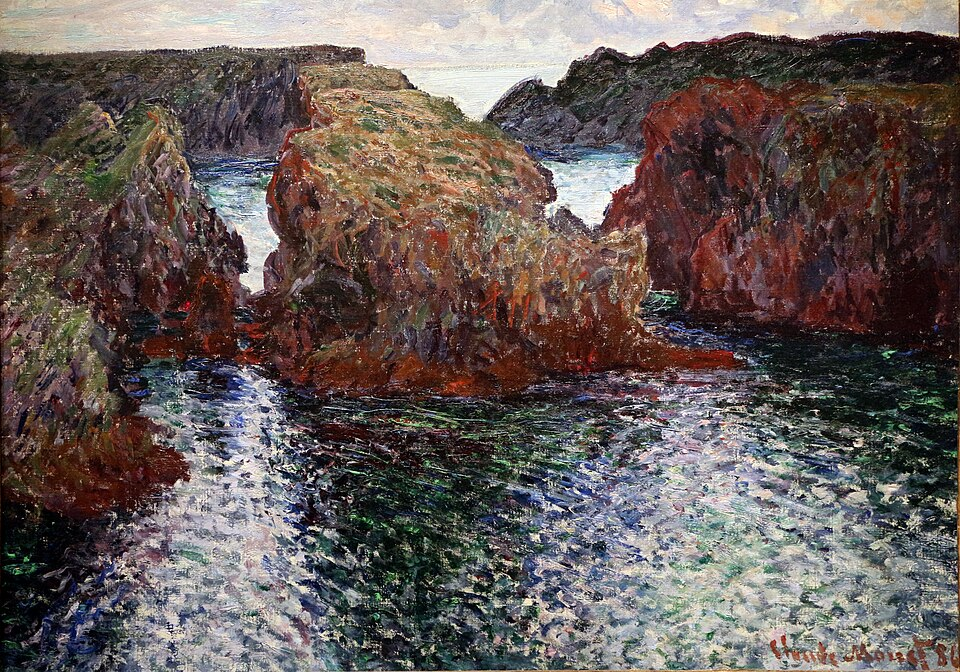

In [ ]:
replacement = next(
    item for item in alternatives
    if "1886, 02.jpg" in item["file_title"]
)

colors, shares = extract_palette(replacement["image"], k=8)

for item in results:
    if item["title"] == replacement["artwork"]["title"]:
        item.update({
            "image": replacement["image"].copy(),
            "palette": colors,
            "proportions": shares,
            "source": replacement["source"],
            "file_title": replacement["file_title"],
        })

# Also preserve the replacement in pending.
for i, item in enumerate(pending):
    if item["artwork"]["id"] == replacement["artwork"]["id"]:
        pending[i] = replacement.copy()

print("Replacement image:")
display(replacement["image"])

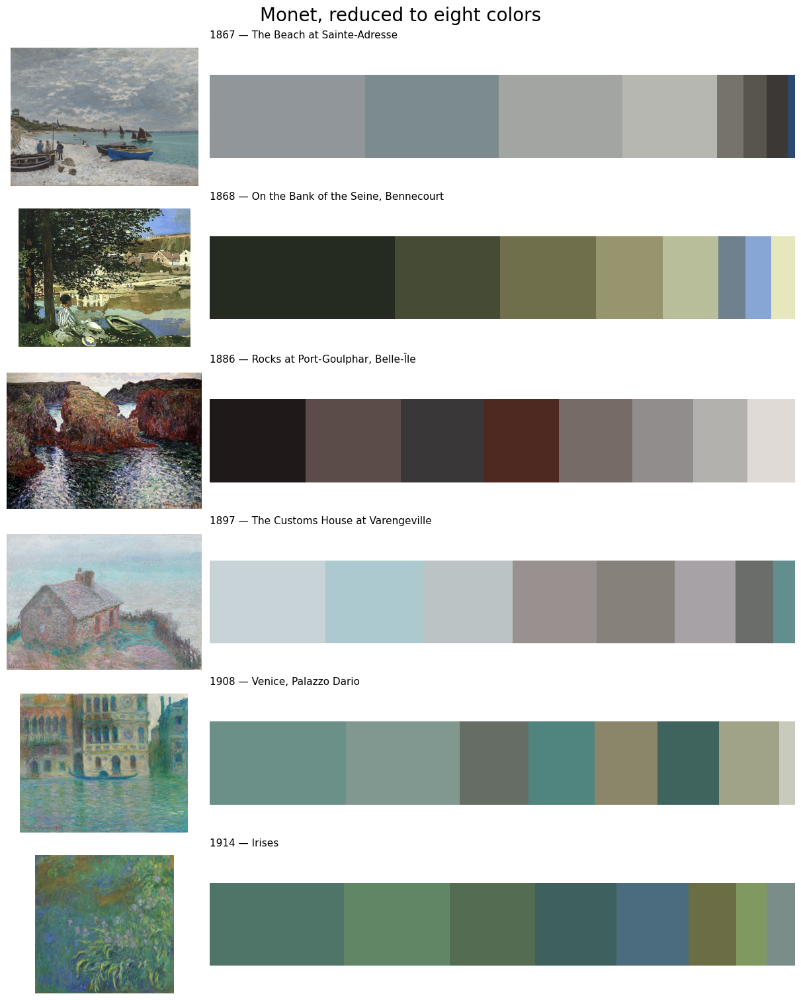

In [ ]:
import textwrap

fig, axes = plt.subplots(
    len(results), 2,
    figsize=(12, 2.5 * len(results)),
    gridspec_kw={"width_ratios": [1, 3]},
    constrained_layout=True,
    squeeze=False,
)

for row, item in enumerate(results):
    image_ax, palette_ax = axes[row]

    image_ax.imshow(item["image"])
    image_ax.axis("off")

    left = 0
    for color, share in zip(item["palette"], item["proportions"]):
        palette_ax.barh(
            0, share, left=left,
            color=color / 255, height=0.6
        )
        left += share

    title = textwrap.fill(item["title"], width=55)
    palette_ax.set_title(
        f"{item['year']} — {title}",
        loc="left", fontsize=11, pad=10
    )
    palette_ax.set_xlim(0, 1)
    palette_ax.set_ylim(-0.5, 0.5)
    palette_ax.axis("off")

fig.suptitle(
    "Monet, reduced to eight colors",
    fontsize=20
)

fig.savefig(
    "monet_palette_timeline.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [ ]:
files.download("monet_palette_timeline.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Finished: The Beach at Sainte-Adresse
Finished: On the Bank of the Seine, Bennecourt
Finished: Rocks at Port-Goulphar, Belle-Île
Finished: The Customs House at Varengeville
Finished: Venice, Palazzo Dario
Finished: Irises


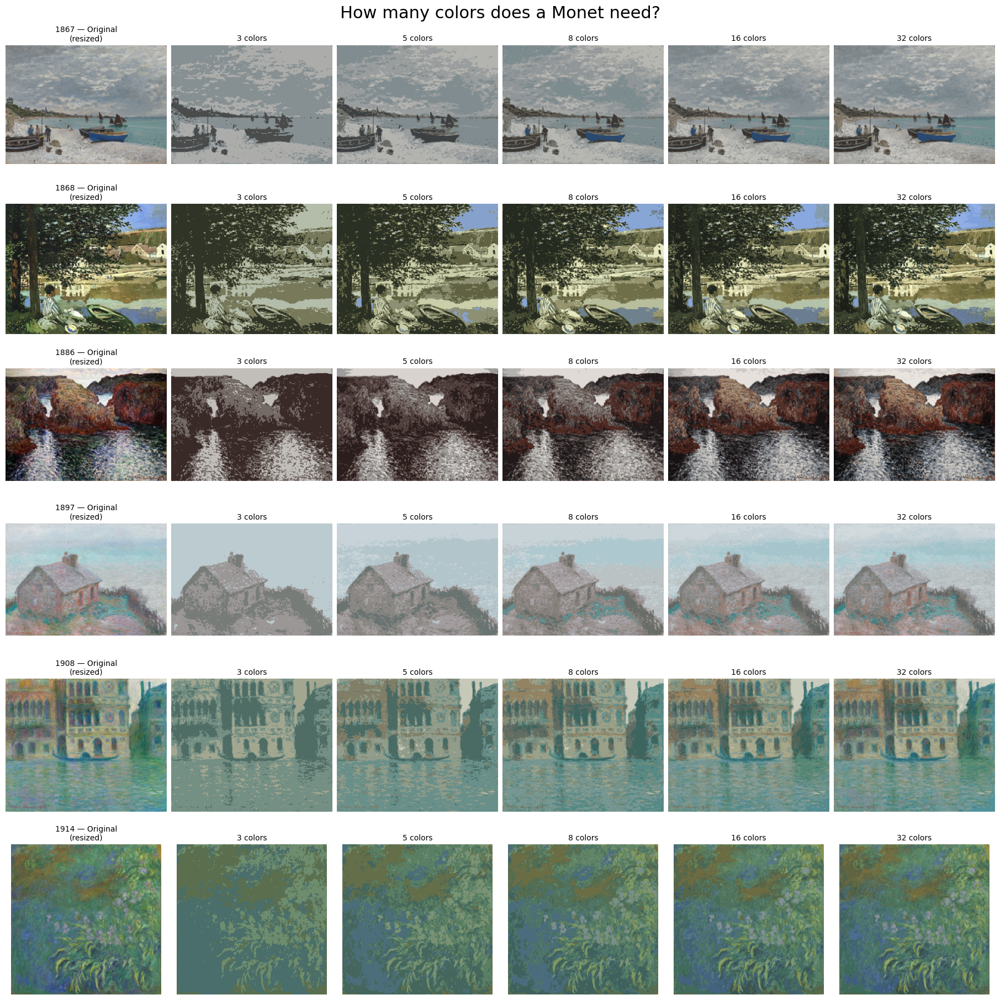

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

color_counts = [3, 5, 8, 16, 32]
reconstructions = []

fig, axes = plt.subplots(
    len(results),
    len(color_counts) + 1,
    figsize=(18, 3 * len(results)),
    squeeze=False,
    constrained_layout=True,
)

for row, item in enumerate(results):
    # Use the same resized image for every version.
    small = item["image"].copy()
    small.thumbnail((240, 240))

    original = np.asarray(small).copy()
    pixels = original.reshape(-1, 3).astype(np.float64)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{item['year']} — Original\n(resized)", fontsize=10
    )

    record = {
        "title": item["title"],
        "year": item["year"],
        "original": original,
        "versions": {},
    }

    for column, k in enumerate(color_counts, start=1):
        model = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=0,
        )
        labels = model.fit_predict(pixels)

        # Replace each pixel with its cluster's average color.
        reconstructed_pixels = model.cluster_centers_[labels]

        reconstructed = np.clip(
            np.rint(reconstructed_pixels), 0, 255
        ).astype("uint8").reshape(original.shape)

        # Mean squared RGB error, measured on a 0–1 scale.
        mse = np.mean(
            ((pixels - reconstructed.reshape(-1, 3)) / 255) ** 2
        )

        record["versions"][k] = {
            "image": reconstructed,
            "mse": float(mse),
        }

        axes[row, column].imshow(reconstructed)
        axes[row, column].set_title(f"{k} colors", fontsize=10)

    for ax in axes[row]:
        ax.axis("off")

    reconstructions.append(record)
    print("Finished:", item["title"])

fig.suptitle("How many colors does a Monet need?", fontsize=22)

fig.savefig(
    "monet_color_reconstructions.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

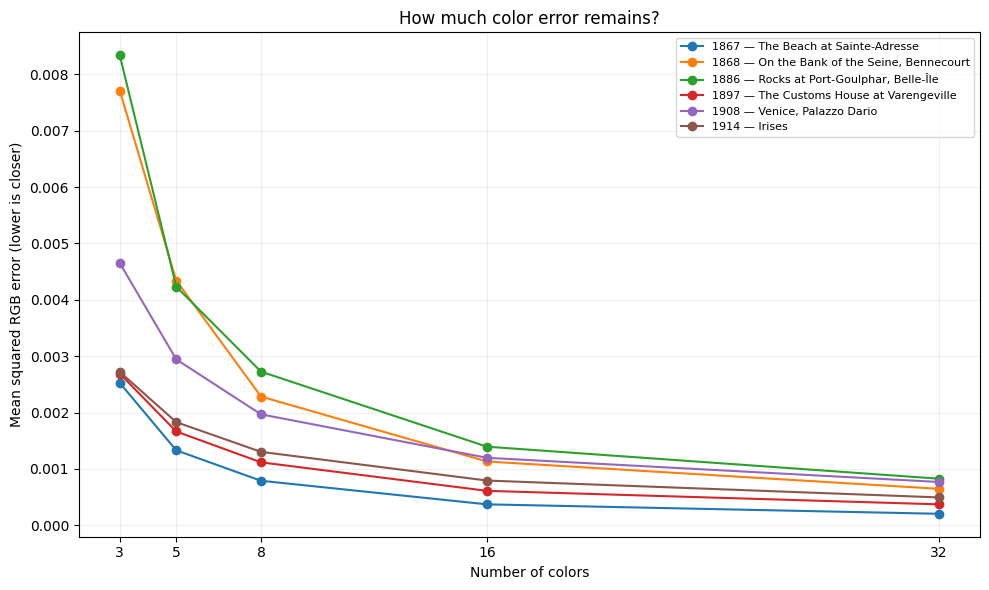

In [27]:
import pandas as pd

error_rows = []

for item in reconstructions:
    for k, version in item["versions"].items():
        error_rows.append({
            "title": item["title"],
            "year": item["year"],
            "colors": k,
            "mse": version["mse"],
        })

errors = pd.DataFrame(error_rows)

fig, ax = plt.subplots(figsize=(10, 6))

for item in reconstructions:
    subset = errors[
        (errors["title"] == item["title"])
        & (errors["year"] == item["year"])
    ].sort_values("colors")

    ax.plot(
        subset["colors"],
        subset["mse"],
        marker="o",
        label=f"{item['year']} — {item['title']}",
    )

ax.set(
    title="How much color error remains?",
    xlabel="Number of colors",
    ylabel="Mean squared RGB error (lower is closer)",
)
ax.set_xticks(color_counts)
ax.grid(alpha=0.2)
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig("monet_color_error.png", dpi=200)
plt.show()

errors.to_csv("monet_color_error.csv", index=False)